# QAOA Comparison

Compares **CD-ADAPT-VQE** ($\ell=1$ and $\ell=2$) against **QAOA/QOAO** on $n=6$, analyzing two types of instances:

- **Benchmark instances**: the 4 benchmark graphs from Xichen's paper, saved in `datos/grafos_comparacion.txt`.
- **Regular graphs**: the 2 regular graphs used in the manuscript (degree 4 = $G_5$ and degree 5 = $K_6$), already separated from degree 2 and 3 (not cited in the manuscript; see `resultados/*/no_usado_en_escrito/`).

The complete results (JSON) of both algorithms for these instances are in `resultados/json/`.

## 0. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib as mpl
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("seaborn-whitegrid")

mpl.rcParams.update({
    "figure.dpi"       : 120,
    "figure.facecolor" : "white",
    "axes.facecolor"   : "white",
    "axes.spines.top"  : False,
    "axes.spines.right": False,
    "axes.grid"        : True,
    "grid.color"       : "#DDDDDD",
    "grid.linewidth"   : 0.6,
    "grid.alpha"       : 1.0,
    "font.family"      : "serif",
    "font.size"        : 11,
    "axes.labelsize"   : 11,
    "axes.titlesize"   : 12,
    "axes.titleweight" : "bold",
    "legend.fontsize"  : 10,
    "legend.framealpha": 0.9,
    "legend.edgecolor" : "#BBBBBB",
    "xtick.labelsize"  : 10,
    "ytick.labelsize"  : 10,
    "lines.linewidth"  : 2.0,
    "patch.linewidth"  : 0.4,
    "savefig.dpi"      : 150,
    "savefig.bbox"     : "tight",
    "savefig.facecolor": "white",
})

# Colorblind-safe palette (Wong 2011)
C1 = "#0072B2"   # blue      – CD-ADAPT l = 1
C2 = "#D55E00"   # vermilion – CD-ADAPT l = 2
C3 = "#009E73"   # green     – QAOA

import sys
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from functions.utilidades_QAOA import (
    cargar_resultados_json,
    error_relativo_desde_energias,
    cortar_por_max_params,
    cortar_qaoa_con_banda,
    cargar_imagen_con_fondo_transparente,
    agregar_imagen_dentro,
    convertir_adapt_a_diccionario_por_grafo,
    curva_adapt,
    convertir_qaoa_a_diccionario_por_grafo,
    extraer_errores_desde_all_runs,
    curva_qaoa_con_banda_desde_all_runs,
)

In [2]:
# CONFIGURATION
# ============================================================

max_params_plot = None

# "iqr" uses the 25-75 percentiles; "std" uses mean ± standard deviation.
qaoa_band_type = "iqr"

# False: uses only random_1, random_2, ...; True: also includes warm-start.
incluir_warmstart_qaoa = False

# Show the best QAOA restart in addition to the median/band.
mostrar_best_qaoa = False

mostrar_imagen_grafo = True
zoom_imagen_grafo = 0.075

# (0,0) = bottom-left corner, (1,1) = top-right corner (axes fraction)
posicion_imagen_grafo = (0.1, 0.43)


## 1. Data loading

**Benchmark graphs ("benchmark instances").** These are the 4 graphs with $n=6$ in `datos/grafos_comparacion.txt`. Here we load the complete CD-ADAPT-VQE ($\ell=1,2$) and QAOA JSON files for these same graphs, and check which `grafo_id` appears in all three files at once.

In [3]:
# PATHS TO THE COMPLETE JSON FILES
# ============================================================

json_l1_bench = Path("results/json/resultados_completos_comparacion_n6_l1.json")
json_l2_bench = Path("results/json/resultados_completos_comparacion_n6_l2.json")
json_qaoa_bench = Path("results/json/resultados_qaoa_n6_p20_jx_r25_grafos_1_all.json")


# ============================================================
# PATHS TO GRAPH IMAGES
# ============================================================

imagenes_grafos_dir_bench = Path("data/imagenes/comparaciones")

imagenes_grafos_bench = {
    1: imagenes_grafos_dir_bench / "grafo_1.png",
    2: imagenes_grafos_dir_bench / "grafo_2.png",
    3: imagenes_grafos_dir_bench / "grafo_3.png",
    4: imagenes_grafos_dir_bench / "grafo_4.png",
}


# ============================================================
# LOAD DATA
# ============================================================

data_l1_bench = cargar_resultados_json(json_l1_bench)
data_l2_bench = cargar_resultados_json(json_l2_bench)
data_qaoa_bench = cargar_resultados_json(json_qaoa_bench)

res_l1_bench = convertir_adapt_a_diccionario_por_grafo(data_l1_bench)
res_l2_bench = convertir_adapt_a_diccionario_por_grafo(data_l2_bench)
res_qaoa_bench = convertir_qaoa_a_diccionario_por_grafo(data_qaoa_bench)

grafos_comunes_bench = sorted(
    set(res_l1_bench.keys()) &
    set(res_l2_bench.keys()) &
    set(res_qaoa_bench.keys())
)

print("Graphs found in all three files:", grafos_comunes_bench)


Graphs found in all three files: [1, 2, 3, 4]


## 2. Benchmark graphs analysis

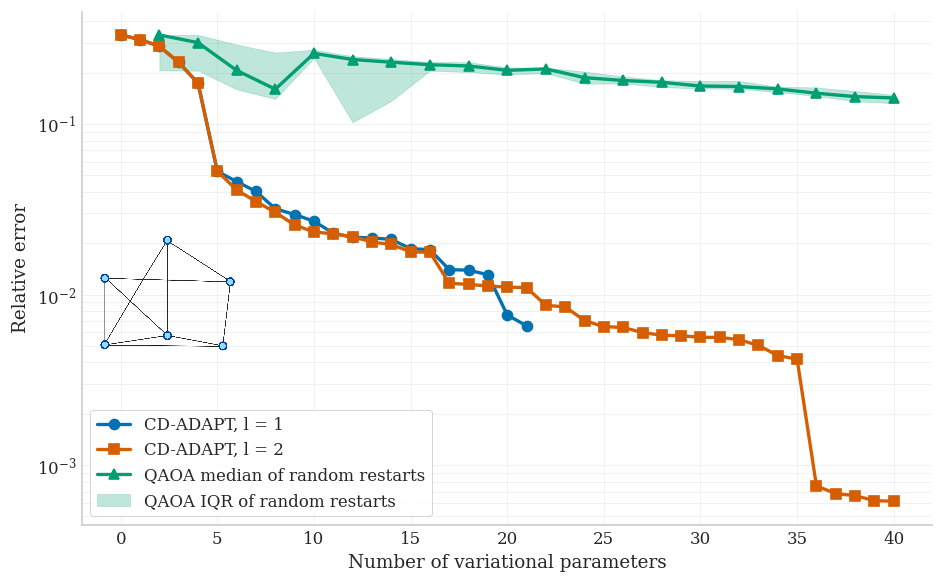

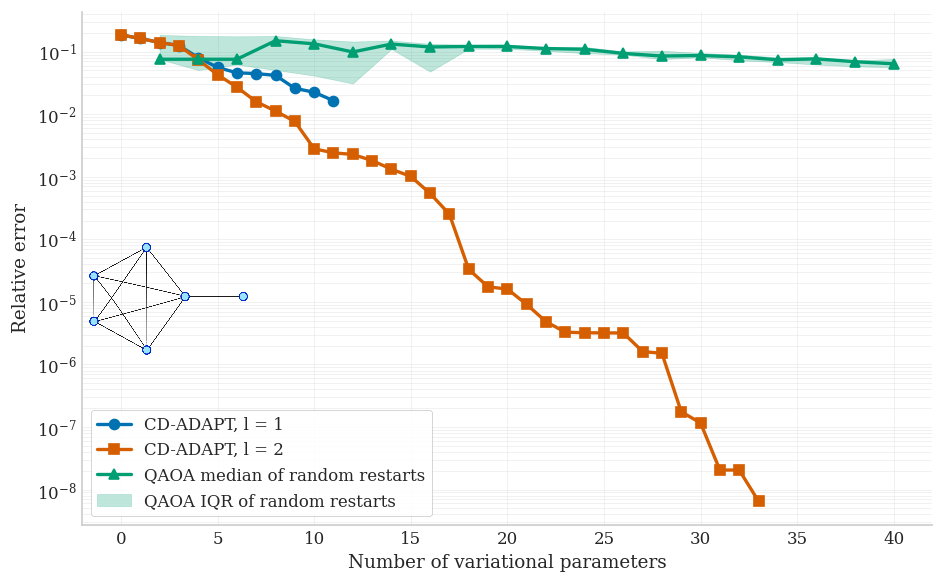

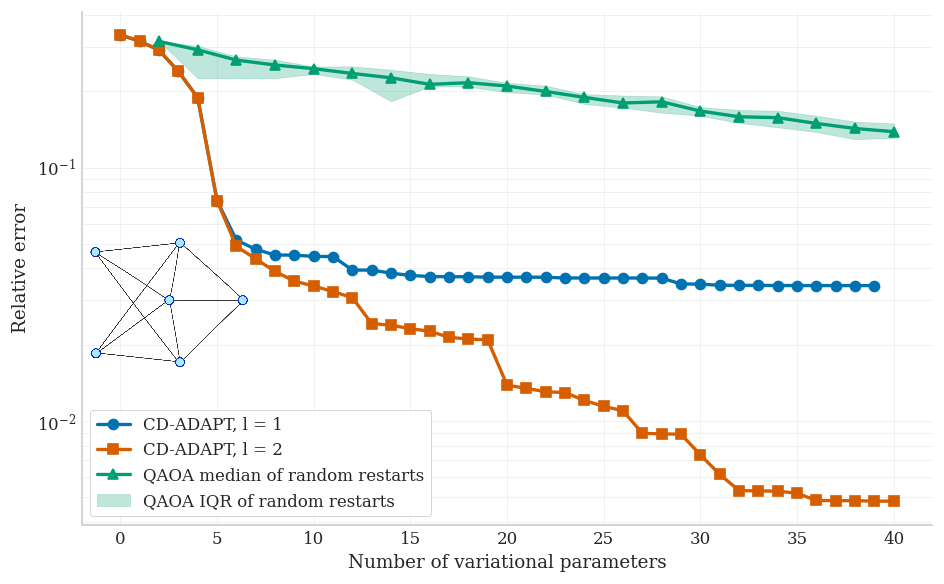

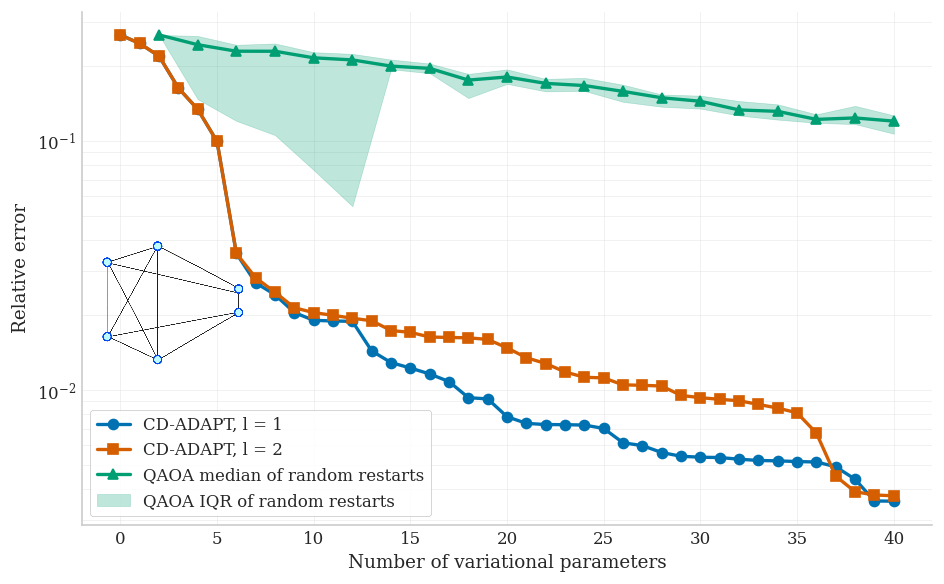

In [4]:
# ============================================================
# GENERATE ONE PLOT PER GRAPH — Benchmark instances
# ============================================================

for grafo_id in grafos_comunes_bench:

    r1 = res_l1_bench[grafo_id]
    r2 = res_l2_bench[grafo_id]
    rq = res_qaoa_bench[grafo_id]

    # ADAPT curves
    x_l1, err_l1 = curva_adapt(r1)
    x_l2, err_l2 = curva_adapt(r2)

    # QAOA curve with band from all_runs
    (
        x_qaoa,
        err_qaoa_central,
        err_qaoa_low,
        err_qaoa_high,
        err_qaoa_best,
    ) = curva_qaoa_con_banda_desde_all_runs(
        rq,
        band_type=qaoa_band_type,
        incluir_warmstart=incluir_warmstart_qaoa,
    )

    # Truncate ADAPT
    x_l1, err_l1 = cortar_por_max_params(x_l1, err_l1, max_params_plot)
    x_l2, err_l2 = cortar_por_max_params(x_l2, err_l2, max_params_plot)

    # Truncate QAOA
    (
        x_qaoa,
        err_qaoa_central,
        err_qaoa_low,
        err_qaoa_high,
        err_qaoa_best,
    ) = cortar_qaoa_con_banda(
        x_qaoa,
        err_qaoa_central,
        err_qaoa_low,
        err_qaoa_high,
        err_qaoa_best,
        max_params_plot,
    )

    # ========================================================
    # PLOT
    # ========================================================

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(
        x_l1,
        err_l1,
        marker="o",
        color=C1,
        label="CD-ADAPT, l = 1"
    )

    ax.plot(
        x_l2,
        err_l2,
        marker="s",
        color=C2,
        label="CD-ADAPT, l = 2"
    )

    ax.plot(
        x_qaoa,
        err_qaoa_central,
        marker="^",
        color=C3,
        label="QAOA median of random restarts"
        if qaoa_band_type == "iqr"
        else "QAOA mean of random restarts"
    )

    ax.fill_between(
        x_qaoa,
        err_qaoa_low,
        err_qaoa_high,
        alpha=0.25,
        color=C3,
        label="QAOA IQR of random restarts"
        if qaoa_band_type == "iqr"
        else "QAOA ± std of random restarts"
    )

    if mostrar_best_qaoa:
        ax.plot(
            x_qaoa,
            err_qaoa_best,
            linestyle="--",
            marker="x",
            color=C3,
            alpha=0.8,
            label="Best QAOA restart"
        )

    ax.set_yscale("log")
    ax.set_xlabel("Number of variational parameters")
    ax.set_ylabel("Relative error")
    #x.set_title(f"Benchmark graph {grafo_id}: relative error vs. number of parameters")
    ax.grid(True, which="both", alpha=0.4)

    # Image inside the plot, right above the legend
    if mostrar_imagen_grafo and grafo_id in imagenes_grafos_bench:
        agregar_imagen_dentro(
            ax,
            imagenes_grafos_bench[grafo_id],
            zoom=zoom_imagen_grafo,
            xy=posicion_imagen_grafo
        )

    # Legend at the bottom left
    ax.legend(
        loc="lower left",
        frameon=True,
        framealpha=0.9
    )

    plt.tight_layout()
    plt.show()
    plt.close()


## 3. Regular graphs analysis

**Regular graphs.** These are the 2 regular graphs used in the manuscript (degree 4 = $G_5$ and degree 5 = $K_6$), already separated from degree 2 and 3 (not cited in the manuscript; kept in `resultados/*/no_usado_en_escrito/`). Here we load their complete JSON files and check that `grafo_id` is present in all three files.

**$K_6$, $l=2$:** the laptop run in these JSON files does not reach the 18-parameter, machine-precision convergence reported in the manuscript. The cell below replaces that single curve with H. Díaz-Moraga's run (`local_minima/data/K6_l2.json`), which is the one actually shown in the paper (Table I, Fig. 3b).

In [5]:
# PATHS TO THE COMPLETE JSON FILES (already split: degree 4 and degree 5 only)
# ============================================================

json_l1_reg = Path("results/json/resultados_completos_regulares_grado4_grado5_n6_l1.json")
json_l2_reg = Path("results/json/resultados_completos_regulares_grado4_grado5_n6_l2.json")
json_qaoa_reg = Path("results/json/resultados_qaoa_regulares_grado4_grado5_n6_p20_jx_r25.json")


# ============================================================
# PATHS TO GRAPH IMAGES
# ============================================================

imagenes_grafos_dir_reg = Path("data/imagenes/regulares")

imagenes_grafos_reg = {
    3: imagenes_grafos_dir_reg / "grado_4.png",
    4: imagenes_grafos_dir_reg / "grado_5.png",
}


# ============================================================
# LOAD DATA
# ============================================================

data_l1_reg = cargar_resultados_json(json_l1_reg)
data_l2_reg = cargar_resultados_json(json_l2_reg)
data_qaoa_reg = cargar_resultados_json(json_qaoa_reg)

res_l1_reg = convertir_adapt_a_diccionario_por_grafo(data_l1_reg)
res_l2_reg = convertir_adapt_a_diccionario_por_grafo(data_l2_reg)
res_qaoa_reg = convertir_qaoa_a_diccionario_por_grafo(data_qaoa_reg)

grafos_comunes_reg = sorted(
    set(res_l1_reg.keys()) &
    set(res_l2_reg.keys()) &
    set(res_qaoa_reg.keys())
)

print("Graphs found in all three files:", grafos_comunes_reg)


Graphs found in all three files: [3, 4]


In [6]:
# Replace the K_6, l=2 curve (grafo_id=4) with H. Díaz-Moraga's run from local_minima/,
# the one shown in the paper (Table I: 18 parameters, machine precision).
k6_l2_path = PROJECT_ROOT / "local_minima" / "data" / "K6_l2.json"
with open(k6_l2_path, "r", encoding="utf-8") as f:
    _k6_l2 = json.load(f)

res_l2_reg[4] = {
    "grafo_id": 4,
    "ground_energy": _k6_l2["ground_energy"],
    "energy_trace": _k6_l2["recycled_energy"],
    "num_ansatz_ops": _k6_l2["num_ansatz_ops"],
}


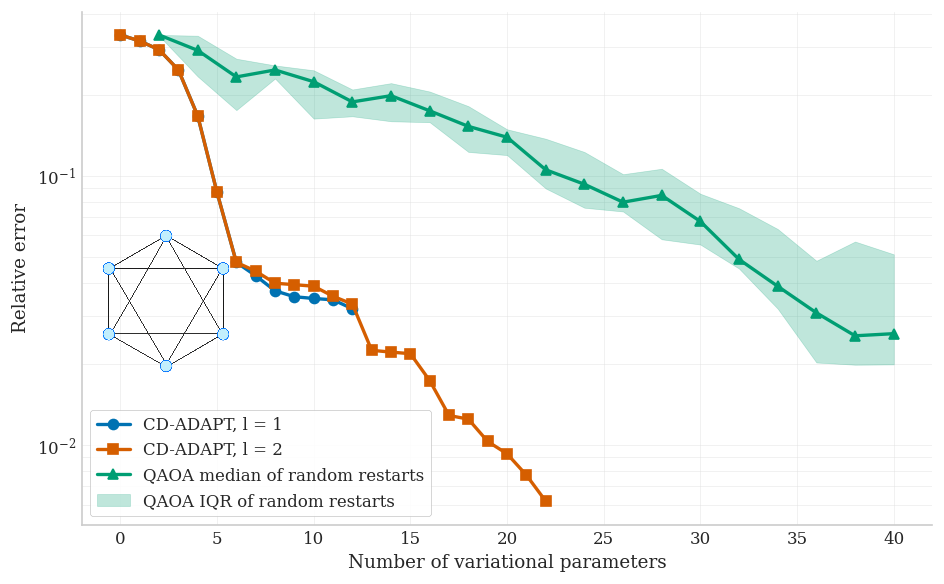

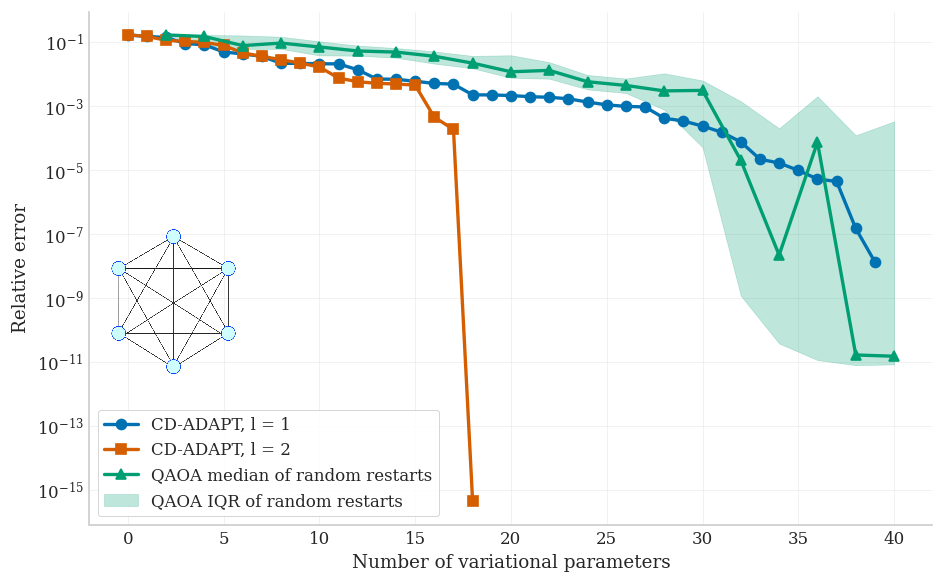

In [7]:
# Mapping grafo_id -> degree of the regular graph
GRADO_REGULAR = {3: 4, 4: 5}  # already split: only the 2 degrees used in the manuscript

# ============================================================
# GENERATE ONE PLOT PER GRAPH — Regular graph instances
# ============================================================

for grafo_id in grafos_comunes_reg:

    r1 = res_l1_reg[grafo_id]
    r2 = res_l2_reg[grafo_id]
    rq = res_qaoa_reg[grafo_id]

    # ADAPT curves
    x_l1, err_l1 = curva_adapt(r1)
    x_l2, err_l2 = curva_adapt(r2)

    # QAOA curve with band from all_runs
    (
        x_qaoa,
        err_qaoa_central,
        err_qaoa_low,
        err_qaoa_high,
        err_qaoa_best,
    ) = curva_qaoa_con_banda_desde_all_runs(
        rq,
        band_type=qaoa_band_type,
        incluir_warmstart=incluir_warmstart_qaoa,
    )

    # Truncate ADAPT
    x_l1, err_l1 = cortar_por_max_params(x_l1, err_l1, max_params_plot)
    x_l2, err_l2 = cortar_por_max_params(x_l2, err_l2, max_params_plot)

    # Truncate QAOA
    (
        x_qaoa,
        err_qaoa_central,
        err_qaoa_low,
        err_qaoa_high,
        err_qaoa_best,
    ) = cortar_qaoa_con_banda(
        x_qaoa,
        err_qaoa_central,
        err_qaoa_low,
        err_qaoa_high,
        err_qaoa_best,
        max_params_plot,
    )

    # ========================================================
    # PLOT
    # ========================================================

    degree = GRADO_REGULAR.get(grafo_id, grafo_id)

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(
        x_l1,
        err_l1,
        marker="o",
        color=C1,
        label="CD-ADAPT, l = 1"
    )

    ax.plot(
        x_l2,
        err_l2,
        marker="s",
        color=C2,
        label="CD-ADAPT, l = 2"
    )

    ax.plot(
        x_qaoa,
        err_qaoa_central,
        marker="^",
        color=C3,
        label="QAOA median of random restarts"
        if qaoa_band_type == "iqr"
        else "QAOA mean of random restarts"
    )

    ax.fill_between(
        x_qaoa,
        err_qaoa_low,
        err_qaoa_high,
        alpha=0.25,
        color=C3,
        label="QAOA IQR of random restarts"
        if qaoa_band_type == "iqr"
        else "QAOA ± std of random restarts"
    )

    if mostrar_best_qaoa:
        ax.plot(
            x_qaoa,
            err_qaoa_best,
            linestyle="--",
            marker="x",
            color=C3,
            alpha=0.8,
            label="Best QAOA restart"
        )

    ax.set_yscale("log")
    ax.set_xlabel("Number of variational parameters")
    ax.set_ylabel("Relative error")
    #x.set_title(f"Regular graph (degree {degree}): relative error vs. number of parameters")
    ax.grid(True, which="both", alpha=0.4)

    # Image inside the plot, right above the legend
    if mostrar_imagen_grafo and grafo_id in imagenes_grafos_reg:
        agregar_imagen_dentro(
            ax,
            imagenes_grafos_reg[grafo_id],
            zoom=zoom_imagen_grafo,
            xy=posicion_imagen_grafo
        )

    # Legend at the bottom left
    ax.legend(
        loc="lower left",
        frameon=True,
        framealpha=0.9
    )

    plt.tight_layout()
    plt.show()
    plt.close()
